# Pass-interception survival model

**Analytical question:** Assess a hypothetical passing option.

**Stages in this notebook:** Ball path and timing; player arrival; interception hazard; survival integration.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

**Example controls:** edit the example-selection cell near the top and rerun. Exploration and animation code is inline; no downloaded videos or separate HTML export is required.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## Choose an example with selection variables

First run the notebook top to bottom. For another example, change these variables, run this selection cell, then rerun the final exploration cell. Refit models only when you intend to. Near the end, `available_possessions` and `available_events` list available choices; use their displayed identifiers. You can inspect more rows with `display(available_possessions)` or `display(available_events)`. A frame override takes priority over a possession or event. Method-specific selectors are documented in the comments.

The final explorer computes its overlays directly from real tracking frames and the method functions in this notebook. Animation frames are rendered inline using Matplotlib; no MP4 or other movie is downloaded. Missing coverage stops the clip rather than interpolating motion. The saved notebook contains a playable default animation, but choosing another example requires rerunning Python. All helpers remain inline.

In [2]:
# Example selection: change a selection, then rerun the cells below. None uses the worked default.
PERIOD = 1
FRAME_ID = None         # exact raw tracking frame; overrides event/possession start
POSSESSION_INDEX = None    # possession_index from available_possessions near the end
EVENT_ID = None         # actual supplied event_id from available_events, not row number
PLAYER_ID = None        # player_id (string or integer), from metadata
TEAM_ID = None          # team_id; None uses the initial possession team
DURATION_S = 6.0     # maximum; clips stop at coverage/selection boundaries
FRAME_STRIDE = 3           # use 1 for every 10 Hz frame; 3 gives a faster preview
RECEIVER_ID = None  # player_id; None uses the worked example receiver


## 2. Inline ingestion and plotting helpers

In [3]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [4]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(FRAME_ID) if FRAME_ID is not None else int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Specify the hypothetical pass

Prepare real player coordinates, then choose a start and destination before computing interception.

,player_id,x,y,x_previous,y_previous
0,11897,-23.76,-8.98,-23.58,-9.12
1,287934,5.39,5.03,5.52,5.14
2,50982,-25.71,23.32,-25.47,23.19
3,50999,36.45,0.86,36.52,0.89
4,51002,-4.41,1.65,-4.07,1.49


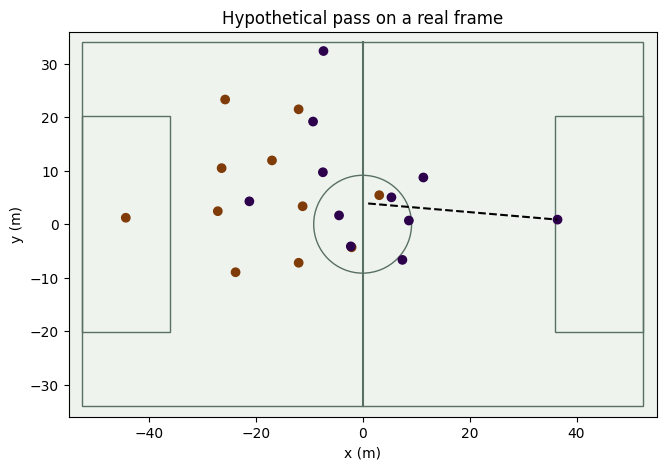

In [5]:
X,Y=np.meshgrid(np.linspace(-52.5,52.5,70),np.linspace(-34,34,46));targets=np.stack([X,Y],axis=-1)
nodes=snapshot.reset_index(drop=True);positions=nodes[['x','y']].to_numpy();home=nodes.team_id.eq(1802).to_numpy()
previous=observed[observed.frame_id.eq(frame_id-1)][['player_id','x','y','seconds']]
nodes=nodes.merge(previous,on='player_id',suffixes=('','_previous'),how='left');dt=nodes.seconds-nodes.seconds_previous
velocity=(nodes[['x','y']].to_numpy()-nodes[['x_previous','y_previous']].to_numpy())/dt.to_numpy()[:,None]
velocity=np.nan_to_num(velocity,nan=0.,posinf=0.,neginf=0.)
display(nodes[['player_id','x','y','x_previous','y_previous']].head())

ball=wide[wide.frame_id.eq(frame_id)].iloc[0];start=np.array([ball.ball_x,ball.ball_y]);options=nodes[nodes.team_id.eq(1802)].copy()
destination=options.loc[np.hypot(options.x-start[0],options.y-start[1]).idxmax(),['x','y']].to_numpy(dtype=float)
fig,ax=plt.subplots(figsize=(9,5));pitch(ax);ax.scatter(positions[:,0],positions[:,1],c=home,cmap='PuOr');ax.plot([start[0],destination[0]],[start[1],destination[1]],'k--');ax.set_title('Hypothetical pass on a real frame');plt.show()

## 5. Inspect ball travel and player arrival

Introduce the component calculator before using it. First inspect only the competing arrival times.

,ball_time_s,earliest_defender_arrival_s
0,0.000000,1.218802
1,0.060767,1.101081
2,0.121533,1.045026
3,0.182300,1.079059
4,0.243067,1.184557
5,0.303833,1.326396
6,0.364600,1.485121
7,0.425367,1.652326
8,0.486134,1.824234
9,0.546900,1.998978


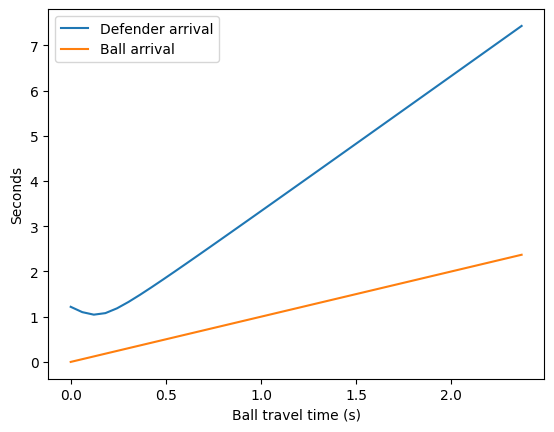

In [6]:
def sigmoid(z):
    return 1/(1+np.exp(-np.clip(z,-40,40)))

def interception_components(start,end,defenders,ball_speed=15.,reaction=.7,run_speed=5.,rate=2.):
    duration=np.linalg.norm(end-start)/ball_speed
    times=np.linspace(0,max(duration,1e-6),40)
    path=start+(end-start)*np.linspace(0,1,40)[:,None]
    player_arrival=reaction+np.linalg.norm(path[:,None,:]-defenders[None,:,:],axis=-1)/run_speed
    hazard=rate*sigmoid((times[:,None]-player_arrival)/.15)
    increments=(hazard.sum(axis=1)[1:]+hazard.sum(axis=1)[:-1])/2*np.diff(times)
    survival=np.exp(-np.r_[0,np.cumsum(increments)])
    return times,player_arrival,hazard,survival
times,player_arrival,hazard,survival=interception_components(start,destination,positions[~home])
display(pd.DataFrame({'ball_time_s':times,'earliest_defender_arrival_s':player_arrival.min(axis=1)}).head(12))
plt.plot(times,player_arrival.min(axis=1),label='Defender arrival');plt.plot(times,times,label='Ball arrival');plt.xlabel('Ball travel time (s)');plt.ylabel('Seconds');plt.legend();plt.show()

## 6. Calculate local interception hazards

The arrival-time difference feeds a sigmoid hazard. Sum defender hazards before integrating them.

,0,1,2,3,4,5,6,7,8,9,10
0,8.496709e-18,8.496709e-18,7.361365e-14,1.585236e-07,8.496709e-18,2.420800e-12,8.496709e-18,1.494369e-09,8.496709e-18,0.000592,3.976562e-15
1,8.496709e-18,8.496709e-18,3.493891e-14,1.613912e-07,8.496709e-18,1.521145e-12,8.496709e-18,6.707649e-10,8.496709e-18,0.001944,2.636293e-15
2,8.496709e-18,8.496709e-18,1.649389e-14,1.477740e-07,8.496709e-18,9.281610e-13,8.496709e-18,3.007240e-10,8.496709e-18,0.004230,1.702380e-15
3,8.496709e-18,8.496709e-18,7.749470e-15,1.231487e-07,8.496709e-18,5.516563e-13,8.496709e-18,1.346929e-10,8.496709e-18,0.005053,1.073017e-15
4,8.496709e-18,8.496709e-18,3.625676e-15,9.453349e-08,8.496709e-18,3.202617e-13,8.496709e-18,6.027981e-11,8.496709e-18,0.003752,6.614272e-16


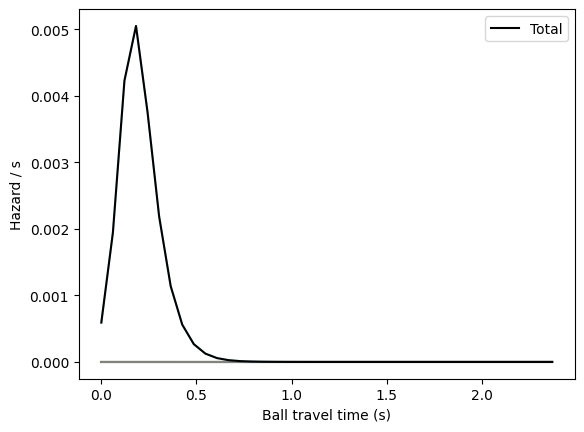

In [7]:
display(pd.DataFrame(hazard).head())
plt.plot(times,hazard,alpha=.3);plt.plot(times,hazard.sum(axis=1),c='black',label='Total');plt.xlabel('Ball travel time (s)');plt.ylabel('Hazard / s');plt.legend();plt.show()

## 7. Integrate survival along the path

Inspect the progressive no-interception probability before selecting its endpoint value.

,ball_time_s,total_hazard,survival
0,0.000000,0.000592,1.000000
1,0.060767,0.001944,0.999923
2,0.121533,0.004230,0.999735
3,0.182300,0.005053,0.999453
4,0.243067,0.003753,0.999186
5,0.303833,0.002187,0.999006
6,0.364600,0.001139,0.998905
7,0.425367,0.000560,0.998853
8,0.486134,0.000267,0.998828
9,0.546900,0.000125,0.998816


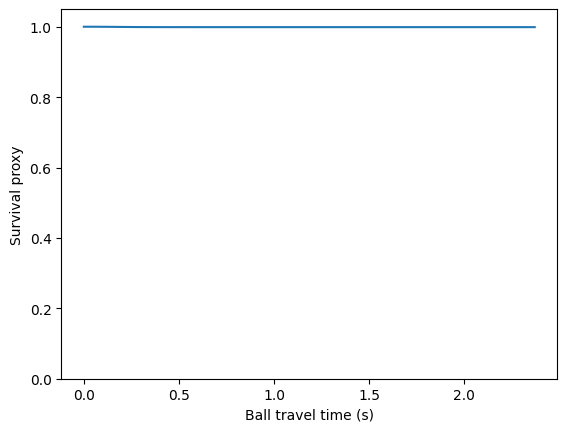

In [8]:
display(pd.DataFrame({'ball_time_s':times,'total_hazard':hazard.sum(axis=1),'survival':survival}).head(12))
plt.plot(times,survival);plt.ylim(0,1.05);plt.xlabel('Ball travel time (s)');plt.ylabel('Survival proxy');plt.show()

## 8. Final output: compare passing options

Reuse the inspected component calculator for every hypothetical teammate destination.

,player_id,x,y,completion_proxy
4,51002,-4.41,1.65,0.999949
8,560882,-7.43,9.72,0.999895
9,560983,7.44,-6.67,0.999853
6,51050,8.65,0.69,0.999493
3,50999,36.45,0.86,0.998806
1,287934,5.39,5.03,0.997385
19,965697,11.36,8.74,0.995116
5,51043,-7.32,32.39,0.993757
17,797298,-9.27,19.20,0.978780
12,560986,-2.21,-4.14,0.977163


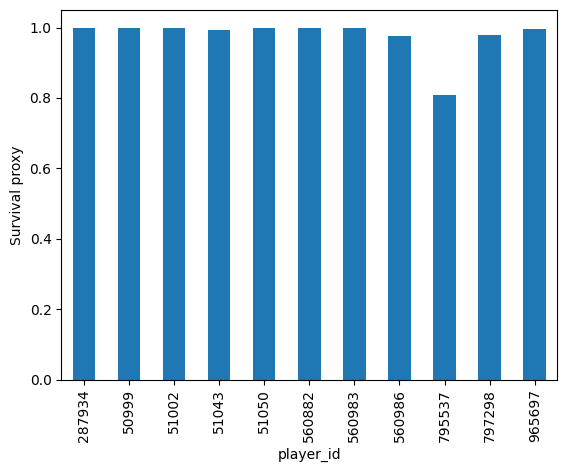

In [9]:
def completion_proxy(start,end,defenders):
    if np.linalg.norm(end-start)<1e-9:return 1.
    return float(interception_components(start,end,defenders)[-1][-1])
options['completion_proxy']=[completion_proxy(start,np.array([r.x,r.y]),positions[~home]) for r in options.itertuples()]
display(options[['player_id','x','y','completion_proxy']].sort_values('completion_proxy',ascending=False));assert options.completion_proxy.between(0,1).all()
options.plot.bar(x='player_id',y='completion_proxy',legend=False);plt.ylabel('Survival proxy');plt.show()

### Passing options and defender interception probes (slide 32)

Use the **same interception-survival calculator** above on a real frame with a known nearby ball carrier and all 22 players. Draw a hypothetical ground pass from the ball to each of the carrier's ten teammates, including the goalkeeper. Each line is labeled with the endpoint survival estimate. We exclude the carrier as a target; opponents are interception threats, not receiving options.

The example is deliberately selected for teaching: a 25–60 m pass with 15–80% estimated survival and at least two defenders whose maximum hazard exceeds 0.9 per second. It is not a random evaluation sample or an observed attempted pass.

For the selected pass, dashed lines connect two threatening defenders to three points along the ball path. The table compares ball and defender arrival times. The local number is **1 − exp(−hazard × 0.2)**: a conditional interception chance over a 0.2 s interval if that single defender's instantaneous hazard stayed fixed and the ball remained free. It is separate from whole-pass survival and should not be summed across probes or defenders. The full calculation integrates summed hazards along the path.

All parameters match the notebook: ball speed 15 m/s, reaction delay 0.7 s, running speed 5 m/s, hazard rate 2/s, sigmoid scale 0.15 s and 40 path points. No receiver-control, offside or calibrated pass-completion model is implied.

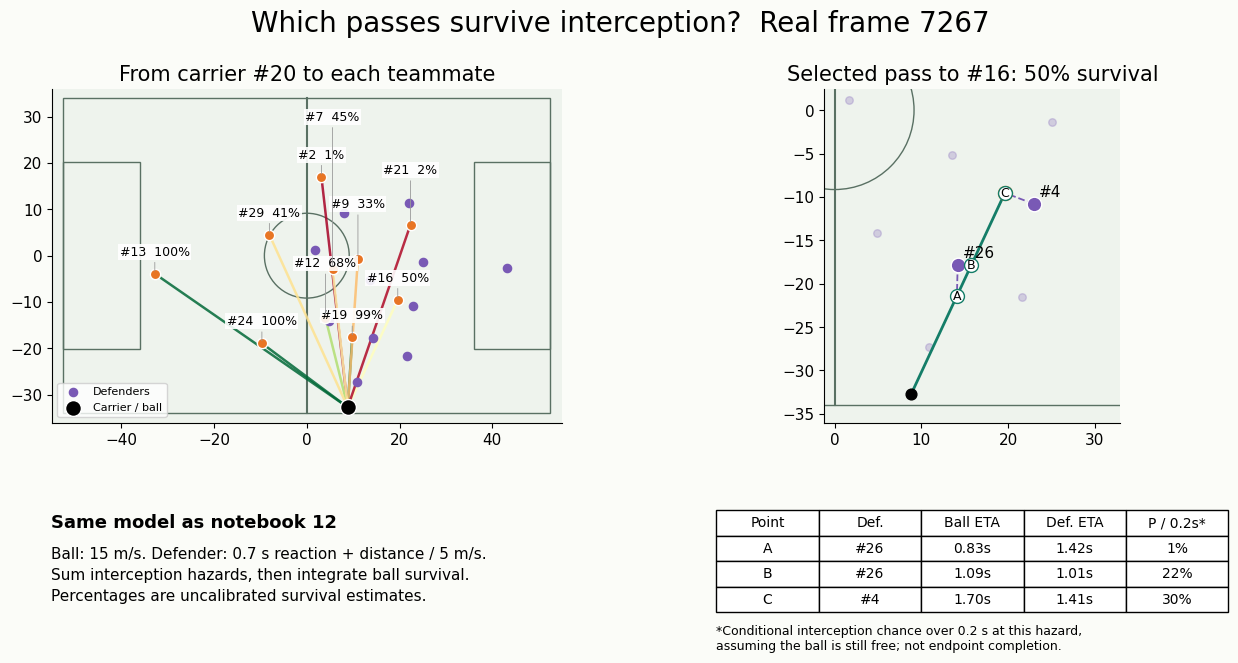

,player_id,name,survival_score
79136,560985,C. Cook,0.999988
85289,809166,A. Lebib,0.999985
72983,11897,J. Risdon,0.989796
66830,51694,T. Gomulka,0.679109
11453,966112,A. Bugarija,0.496444
29912,795530,N. Pennington,0.451830
54524,560989,T. Mrčela,0.409898
60677,560984,D. Williams,0.331575
97595,966114,A. Faisal,0.020631
91442,50982,R. Warland,0.006988


,marker,defender_number,ball_s,defender_s,hazard_per_s,conditional_02s
0,A,26,0.829834,1.417627,0.038963,0.007762
1,B,26,1.091886,1.013370,1.255906,0.222119
2,C,4,1.703343,1.406473,1.757177,0.296323


In [10]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
lookup={str(p['id']):p for p in metadata['players']}
raw_lookup={r['frame']:r for r in raw if r['period']==1}
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size();valid=set(complete[complete.eq(22)].index.get_level_values('frame_id'))
candidates=[]
for frame_id in sorted(valid)[::10]:
    r=raw_lookup.get(frame_id);carrier=str(r.get('possession',{}).get('player_id')) if r else None
    if carrier not in lookup or r['ball_data'].get('z') is None or r['ball_data']['z']>2:continue
    nodes=observed[observed.frame_id.eq(frame_id)].copy();start=np.array([r['ball_data']['x'],r['ball_data']['y']],float)
    owner=nodes[nodes.player_id.eq(carrier)]
    if len(owner)!=1 or np.linalg.norm(owner[['x','y']].to_numpy()[0]-start)>2:continue
    team=int(owner.team_id.iloc[0]);defenders=nodes[nodes.team_id.ne(team)].copy();targets=nodes[nodes.team_id.eq(team)&nodes.player_id.ne(carrier)].copy()
    for target in targets.itertuples():
        end=np.array([target.x,target.y]);length=np.linalg.norm(end-start)
        if not 25<length<60:continue
        times,arrival,hazard,survival=interception_components(start,end,defenders[['x','y']].to_numpy())
        risk=(hazard.max(axis=0)>.9).sum()
        if .15<survival[-1]<.8 and risk>=2:
            candidates.append((abs(survival[-1]-.5),frame_id,carrier,str(target.player_id)))
assert candidates,'No illustrative interception example found'
_,frame_id,carrier,receiver=min(candidates)
r=raw_lookup[frame_id];nodes=observed[observed.frame_id.eq(frame_id)].copy();team=int(lookup[carrier]['team_id']);start=np.array([r['ball_data']['x'],r['ball_data']['y']],float)
defenders=nodes[nodes.team_id.ne(team)].reset_index(drop=True);targets=nodes[nodes.team_id.eq(team)&nodes.player_id.ne(carrier)].copy()
def_xy=defenders[['x','y']].to_numpy();end=targets[targets.player_id.eq(receiver)][['x','y']].to_numpy()[0]
times,arrival,hazard,survival=interception_components(start,end,def_xy);path=start+(end-start)*np.linspace(0,1,40)[:,None]
targets['survival_score']=[interception_components(start,np.array([q.x,q.y]),def_xy)[-1][-1] for q in targets.itertuples()]
# Two defenders with the strongest interception hazards at any path point.
selected=np.argsort(hazard.max(axis=0))[-2:][::-1]
peaks=sorted(int(np.argmax(hazard[:,d])) for d in selected)
indices=sorted(set([max(10,peaks[0]-6),peaks[0],min(39,peaks[-1])]))
assert len(indices)==3
probes=[]
for k,index in enumerate(indices):
    d=int(selected[np.argmax(hazard[index,selected])]);h=float(hazard[index,d]);conditional=1-np.exp(-h*.2)
    probes.append(dict(marker='ABC'[k],index=int(index),defender_id=str(defenders.iloc[d].player_id),defender_number=int(lookup[str(defenders.iloc[d].player_id)]['number']),ball_s=float(times[index]),defender_s=float(arrival[index,d]),hazard_per_s=h,conditional_02s=float(conditional)))
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'#fbfcf8','savefig.facecolor':'#fbfcf8'})
cmap=plt.get_cmap('RdYlGn')

def draw_pass_example(cursor=None):
    fig=plt.figure(figsize=(12.8,7.2),dpi=100);gs=fig.add_gridspec(2,2,height_ratios=[4.1,1.4],hspace=.38,wspace=.3)
    ax=fig.add_subplot(gs[0,0]);pitch(ax)
    ax.scatter(def_xy[:,0],def_xy[:,1],c='#7959b5',s=35,zorder=4,label='Defenders')
    occupied=[]
    for q in targets.itertuples():
        ax.plot([start[0],q.x],[start[1],q.y],color=cmap(q.survival_score),lw=1.8,alpha=.85,zorder=2)
        ax.scatter(q.x,q.y,c='#e87524',edgecolors='white',s=55,zorder=5)
        tx,ty=q.x,q.y+4
        while any(abs(tx-x)<13 and abs(ty-y)<7 for x,y in occupied):ty+=7
        if ty>34:ty=q.y-6
        occupied.append((tx,ty));ax.annotate(f"#{lookup[str(q.player_id)]['number']}  {q.survival_score:.0%}",(q.x,q.y),xytext=(tx,ty),textcoords='data',ha='center',fontsize=9,bbox={'facecolor':'white','alpha':.9,'edgecolor':'none','pad':1},arrowprops={'arrowstyle':'-','color':'#999','lw':.6},zorder=10)
    ax.scatter(*start,s=130,c='black',edgecolors='white',zorder=8,label='Carrier / ball')
    ax.set_title(f"From carrier #{lookup[carrier]['number']} to each teammate",fontsize=15);ax.set_xlabel('');ax.set_ylabel('');ax.legend(loc='lower left',fontsize=8)
    ax=fig.add_subplot(gs[0,1]);pitch(ax)
    ax.scatter(def_xy[:,0],def_xy[:,1],c='#7959b5',alpha=.25,s=30,zorder=2)
    ax.plot(*path.T,c='#147d68',lw=2,label='Ball path');ax.scatter(*start,c='black',s=60,zorder=5);ax.scatter(*end,c='#e87524',s=100,zorder=5)
    for j,d in enumerate(selected):
        q=def_xy[d];ax.scatter(*q,c='#7959b5',edgecolors='white',s=110,zorder=5);ax.annotate('#'+str(lookup[str(defenders.iloc[d].player_id)]['number']),q,xytext=(4,5),textcoords='offset points',fontsize=11)
    for probe in probes:
        point=path[probe['index']];dxy=def_xy[defenders.player_id.eq(probe['defender_id'])][0]
        ax.plot([dxy[0],point[0]],[dxy[1],point[1]],ls='--',c='#7959b5',lw=1.3,alpha=1 if cursor is None or cursor>=probe['index'] else .25)
        ax.scatter(*point,s=100,facecolors='white',edgecolors='#147d68',zorder=7);ax.text(*point,probe['marker'],ha='center',va='center',fontsize=9,zorder=8)
    if cursor is not None:ax.scatter(*path[cursor],s=130,c='black',edgecolors='white',zorder=10)
    extent=np.vstack([start,end,def_xy[selected]]);ax.set(xlim=(max(-55,extent[:,0].min()-10),min(55,extent[:,0].max()+10)),ylim=(max(-36,extent[:,1].min()-12),min(36,extent[:,1].max()+12)),xlabel='',ylabel='')
    ax.set_title(f"Selected pass to #{lookup[receiver]['number']}: {survival[-1]:.0%} survival",fontsize=15)
    left=fig.add_subplot(gs[1,0]);left.axis('off');left.text(0,.95,'Same model as notebook 12',weight='bold',fontsize=13,va='top');left.text(0,.66,'Ball: 15 m/s. Defender: 0.7 s reaction + distance / 5 m/s.\nSum interception hazards, then integrate ball survival.\nPercentages are uncalibrated survival estimates.',fontsize=11,va='top',linespacing=1.5)
    table=fig.add_subplot(gs[1,1]);table.axis('off')
    cells=[[p['marker'],f"#{p['defender_number']}",f"{p['ball_s']:.2f}s",f"{p['defender_s']:.2f}s",f"{p['conditional_02s']:.0%}"] for p in probes]
    tb=table.table(cellText=cells,colLabels=['Point','Def.','Ball ETA','Def. ETA','P / 0.2s*'],loc='upper center',cellLoc='center');tb.auto_set_font_size(False);tb.set_fontsize(10);tb.scale(1,1.6)
    table.text(0,-.03,'*Conditional interception chance over 0.2 s at this hazard,\nassuming the ball is still free; not endpoint completion.',fontsize=9,va='top')
    fig.suptitle(f'Which passes survive interception?  Real frame {frame_id}',fontsize=20)
    fig.subplots_adjust(left=.055,right=.975,top=.87,bottom=.13)
    return fig
fig=draw_pass_example();plt.show()
display(targets[['player_id','name','survival_score']].sort_values('survival_score',ascending=False))
display(pd.DataFrame(probes)[['marker','defender_number','ball_s','defender_s','hazard_per_s','conditional_02s']])
assert len(targets)==10 and carrier not in set(targets.player_id)
assert .15<survival[-1]<.8
assert (hazard.max(axis=0)>.9).sum()>=2


## Explore different examples

Run this after the method calculations above. After the first complete run, edit and run the selection cell near the top, then rerun this exploration cell to analyze another example. The worked intermediate steps stay visible above; this section applies the method again to your selection.

,possession_index,period,start_frame,end_frame,team_id,duration_s
0,0,1,10,39,NaN,3.0
1,1,1,40,306,1802.0,26.7
2,2,1,307,347,871.0,4.1
3,3,1,348,371,1802.0,2.4
4,4,1,372,573,871.0,20.2
5,5,1,574,586,1802.0,1.3
6,6,1,587,592,NaN,0.6
7,7,1,593,598,871.0,0.6
8,8,1,599,784,NaN,18.6
9,9,1,973,987,871.0,1.5


,event_id,event_type,frame_start,frame_end
0,8_0,player_possession,39,39
1,1_0,off_ball_run,43,67
2,8_1,player_possession,57,57
3,7_0,passing_option,57,57
4,8_2,player_possession,89,94
5,7_1,passing_option,89,94
6,7_2,passing_option,91,94
7,9_0,on_ball_engagement,134,143
8,9_1,on_ball_engagement,135,143
9,8_3,player_possession,143,143


Recomputed overlays on 20 real frames; first/last: (1, 7267) (1, 7324)


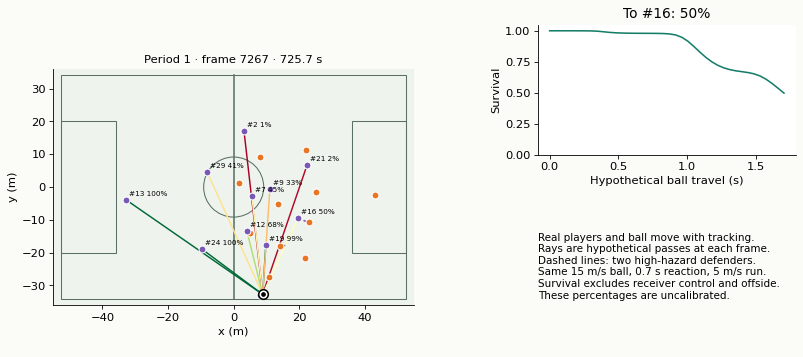

In [11]:
method_name = 'passes'
# All animation inputs and method calculations are local tracking data, not a video asset.
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Polygon, Wedge
from IPython.display import HTML, display

example_meta={str(p['id']):p for p in metadata['players']}
example_home=int(metadata['home_team']['id']);example_away=int(metadata['away_team']['id'])
example_source=list(raw)
if method_name=='graph_epv':
    example_source=list({(int(r['period']),int(r['frame'])):r for r in [*raw,*goal_sequence] if r.get('period') is not None}.values())
source_frames={(int(r['period']),int(r['frame'])):r for r in example_source if r.get('period') is not None}
frames_by_key={key:r for key,r in source_frames.items() if key[0]==PERIOD and len(r.get('player_data',[]))==22 and all(p.get('x') is not None and p.get('y') is not None for p in r['player_data']) and r.get('ball_data',{}).get('x') is not None and r['ball_data'].get('y') is not None and r.get('timestamp') is not None}
assert frames_by_key,'No complete frames for PERIOD in the cached source.'

def tracking_time(record):
    return pd.to_timedelta(record['timestamp']).total_seconds()

def possession_team(record):
    group=record.get('possession',{}).get('group')
    return example_home if group=='home team' else example_away if group=='away team' else None

def attack_direction(team,period):
    home_left=metadata['home_team_side'][period-1]=='right_to_left'
    return -1 if (home_left if team==example_home else not home_left) else 1

def players_at_frame(key):
    r=frames_by_key[key];previous=source_frames.get((key[0],key[1]-1))
    prior={str(p['player_id']):p for p in previous.get('player_data',[])} if previous else {}
    dt=tracking_time(r)-tracking_time(previous) if previous and previous.get('timestamp') else np.nan
    rows=[]
    for p in r['player_data']:
        pid=str(p['player_id']);old=prior.get(pid,{})
        velocity=np.array([np.nan,np.nan])
        if .05<=dt<=.15 and old.get('x') is not None and old.get('y') is not None:
            velocity=(np.array([p['x'],p['y']])-np.array([old['x'],old['y']]))/dt
        rows.append(dict(player_id=pid,team_id=int(example_meta[pid]['team_id']),x=p['x'],y=p['y'],vx=velocity[0],vy=velocity[1],is_detected=p.get('is_detected')))
    return pd.DataFrame(rows)

def draw_tracking_frame(ax,key):
    r=frames_by_key[key];nodes=players_at_frame(key);pitch(ax)
    for team,color in [(example_home,'#e87524'),(example_away,'#7959b5')]:
        q=nodes[nodes.team_id.eq(team)];ax.scatter(q.x,q.y,c=color,edgecolors='white',s=44,zorder=5)
    ball=np.array([r['ball_data']['x'],r['ball_data']['y']])
    ax.scatter(*ball,s=85,c='white',edgecolors='black',lw=1.5,zorder=10)
    ax.scatter(*ball,s=12,c='black',zorder=11)
    ax.set_title(f'Period {key[0]} · frame {key[1]} · {tracking_time(r):.1f} s',fontsize=11)
    return nodes,ball,r

# Possessions here are uninterrupted supplied team-possession spans, not inferred player control.
example_catalog=[];previous=None;group=None
for key in sorted(frames_by_key):
    r=frames_by_key[key];current_possession_team=possession_team(r)
    continuous=previous is not None and key[1]==previous[1]+1 and 0<tracking_time(r)-tracking_time(frames_by_key[previous])<=.15
    if not continuous or current_possession_team!=group:
        example_catalog.append(dict(possession_index=len(example_catalog),period=key[0],start_frame=key[1],end_frame=key[1],team_id=current_possession_team))
    else:example_catalog[-1]['end_frame']=key[1]
    previous=key;group=current_possession_team
available_possessions=pd.DataFrame(example_catalog)
available_possessions['duration_s']=(available_possessions.end_frame-available_possessions.start_frame+1)/10
available_events=events[events.period.eq(PERIOD)&events.frame_start.isin([k[1] for k in frames_by_key])].copy() if 'events' in globals() else pd.DataFrame()
display(available_possessions.head(10))
if len(available_events):display(available_events[['event_id','event_type','frame_start','frame_end']].head(10))

clip_start_frame=None;clip_stop_frame=None;example_action=None
if method_name=='formation':
    available_windows=timeline[timeline.period.eq(PERIOD)].copy();display(available_windows.head(12))
    if FORMATION_WINDOW not in set(available_windows.window):raise ValueError('FORMATION_WINDOW must be a qualifying window in available_windows.')
    example_window_data=team_data[team_data.period_id.eq(PERIOD)&team_data.window.eq(FORMATION_WINDOW)&team_data.team_in_possession.eq(871)]
    example_med=example_window_data.groupby('player_id')[['cx','cy']].median()
    example_points=-example_med.to_numpy();example_fits=[]
    for name,t in templates.items():
        cost=((example_points[:,None]-t[None])**2).sum(2);rr,cc=linear_sum_assignment(cost)
        example_fits.append((name,float(np.sqrt(cost[rr,cc].mean())),cc))
    example_fits.sort(key=lambda a:a[1]);example_best=example_fits[0]
    candidates=[k[1] for k in frames_by_key if FORMATION_WINDOW*30<=tracking_time(frames_by_key[k])<(FORMATION_WINDOW+1)*30]
    assert candidates,'Selected formation window has no complete animation frames.'
    clip_start_frame=min(candidates);clip_stop_frame=max(candidates)
elif method_name=='events':
    display(passes.reset_index(names='pass_index').head(12))
    if len(passes):
        assert 0<=PASS_INDEX<len(passes),'PASS_INDEX is a row number in passes.'
        example_action=passes.iloc[PASS_INDEX];clip_start_frame=max(int(example_action.release)-8,0);clip_stop_frame=int(example_action.reception)+12
elif method_name=='xt':
    example_actions=events[events.event_type.eq('player_possession')&events.end_type.eq('pass')&events.pass_outcome.eq('successful')&events.period.eq(PERIOD)&events.frame_end.isin([k[1] for k in frames_by_key])].dropna(subset=['x_end','y_end','player_targeted_x_reception','player_targeted_y_reception']).copy()
    display(example_actions[['event_id','frame_end','x_end','y_end','player_targeted_x_reception','player_targeted_y_reception']].head(12))
    assert len(example_actions),'No completed actions with endpoint coverage.'
    example_action=example_actions.iloc[0] if EVENT_ID is None else example_actions[example_actions.event_id.eq(EVENT_ID)].iloc[0]
    clip_start_frame=int(example_action.frame_end)-5
elif method_name=='graph_epv' and SEQUENCE=='goal':
    clip_start_frame=int(goal_sequence[0]['frame']);clip_stop_frame=int(goal_sequence[-1]['frame'])
elif method_name=='graph_epv' and SEQUENCE=='non_goal':
    clip_start_frame=int(non_goal_sequence[0]['frame']);clip_stop_frame=int(non_goal_sequence[-1]['frame'])

if EVENT_ID is not None and method_name!='xt':
    chosen=available_events[available_events.event_id.eq(EVENT_ID)]
    assert len(chosen)==1,'Choose EVENT_ID from available_events.event_id, not a row number.'
    clip_start_frame=int(chosen.frame_start.iloc[0]);clip_stop_frame=int(chosen.frame_end.iloc[0])+10
if POSSESSION_INDEX is not None:
    chosen=available_possessions[available_possessions.possession_index.eq(POSSESSION_INDEX)]
    assert len(chosen)==1,'Choose POSSESSION_INDEX from available_possessions.'
    clip_start_frame=int(chosen.start_frame.iloc[0]);clip_stop_frame=int(chosen.end_frame.iloc[0])
if FRAME_ID is not None:
    clip_start_frame=int(FRAME_ID);clip_stop_frame=None
if clip_start_frame is None:clip_start_frame=int(frame_id)
if (PERIOD,clip_start_frame) not in frames_by_key:
    # An event can start on a missing frame. Move forward only within its own interval.
    possible=[k[1] for k in sorted(frames_by_key) if k[1]>=clip_start_frame and (clip_stop_frame is None or k[1]<=clip_stop_frame)]
    assert possible,'No covered frame for this selection.'
    clip_start_frame=possible[0]
clip_keys=[]
for f in range(clip_start_frame,clip_start_frame+max(2,int(DURATION_S*10))):
    key=(PERIOD,f)
    if key not in frames_by_key or (clip_stop_frame is not None and f>clip_stop_frame):break
    if clip_keys and not 0<tracking_time(frames_by_key[key])-tracking_time(frames_by_key[clip_keys[-1]])<=.15:break
    clip_keys.append(key)
assert len(clip_keys)>=2,'Selection ends at a coverage boundary; choose another covered start.'
assert FRAME_STRIDE>=1
clip_keys=clip_keys[::FRAME_STRIDE]
assert len(clip_keys)>=2,'Reduce FRAME_STRIDE or increase clip duration.'
selected_team=TEAM_ID if TEAM_ID is not None else possession_team(frames_by_key[clip_keys[0]]) or example_home
focus_player_id=str(PLAYER_ID) if PLAYER_ID is not None else str(next(p['id'] for p in metadata['players'] if int(p['team_id'])==selected_team))
if method_name=='physical' and PLAYER_ID is None:focus_player_id=str(summary.sort_values('sprint_m',ascending=False).player_id.iloc[0])
example_origin=tracking_time(frames_by_key[clip_keys[0]])
example_trace_keys=clip_keys

example_receiver=str(RECEIVER_ID) if RECEIVER_ID is not None else str(receiver)

def draw_method_overlay(key,ax,bx,cx):
    for a in [ax,bx,cx]:a.clear()
    nodes,ball,r=draw_tracking_frame(ax,key);t=tracking_time(r)-example_origin
    cx.axis('off')
    team=possession_team(r)
    if team is None:bx.text(.1,.5,'Possession team unknown.');return
    defenders=nodes[nodes.team_id.ne(team)];options=nodes[nodes.team_id.eq(team)]
    carrier=str(r.get('possession',{}).get('player_id'));options=options[options.player_id.ne(carrier)]
    for p in options.itertuples():
        end=np.array([p.x,p.y]);score=completion_proxy(ball,end,defenders[['x','y']].to_numpy())
        ax.plot([ball[0],p.x],[ball[1],p.y],c=plt.cm.RdYlGn(score),lw=1.4,zorder=2)
        ax.annotate(f"#{example_meta[p.player_id]['number']} {score:.0%}",(p.x,p.y),xytext=(3,4),textcoords='offset points',fontsize=7,zorder=12)
    selected=options[options.player_id.eq(example_receiver)]
    if not len(selected):bx.text(.1,.5,'RECEIVER_ID is not a teammate now.');return
    end=selected[['x','y']].to_numpy()[0];times,arr,haz,surv=interception_components(ball,end,defenders[['x','y']].to_numpy());path=ball+(end-ball)*np.linspace(0,1,40)[:,None]
    for d in np.argsort(haz.max(0))[-2:]:
        j=int(haz[:,d].argmax());q=defenders[['x','y']].to_numpy()[d];ax.plot([q[0],path[j,0]],[q[1],path[j,1]],'--',c='#7959b5',lw=1.5)
    bx.plot(times,surv,c='#147d68');bx.set(ylim=(0,1.05),xlabel='Hypothetical ball travel (s)',ylabel='Survival',title=f'To #{example_meta[example_receiver]["number"]}: {surv[-1]:.0%}')
    cx.text(0,.9,'Real players and ball move with tracking.\nRays are hypothetical passes at each frame.\nDashed lines: two high-hazard defenders.\nSame 15 m/s ball, 0.7 s reaction, 5 m/s run.\nSurvival excludes receiver control and offside.\nThese percentages are uncalibrated.',va='top',fontsize=10)

def make_example_figure(key):
    fig=plt.figure(figsize=(11,5.7),dpi=75)
    gs=fig.add_gridspec(2,2,width_ratios=[1.4,1],hspace=.5)
    ax=fig.add_subplot(gs[:,0]);bx=fig.add_subplot(gs[0,1]);cx=fig.add_subplot(gs[1,1])
    draw_method_overlay(key,ax,bx,cx);fig.subplots_adjust(left=.07,right=.97,bottom=.14,top=.9,wspace=.4,hspace=.65);return fig,(ax,bx,cx)

# Check two distinct frames before rendering. Animation never interpolates tracking gaps.
for example_check_key in [clip_keys[0],clip_keys[-1]]:
    example_check_figure,_=make_example_figure(example_check_key);plt.close(example_check_figure)
print('Recomputed overlays on',len(clip_keys),'real frames; first/last:',clip_keys[0],clip_keys[-1])
example_static,_=make_example_figure(clip_keys[0]);plt.show()
example_fig,example_axes=make_example_figure(clip_keys[0])
def update_animation(i):
    draw_method_overlay(clip_keys[i],*example_axes)
animation=FuncAnimation(example_fig,update_animation,frames=len(clip_keys),interval=100*FRAME_STRIDE,repeat=False,blit=False)
plt.close(example_fig)
display(HTML(animation.to_jshtml(fps=10/FRAME_STRIDE,default_mode='once')))


## Interpretation and limitations

This is an independent-hazard teaching model with assumed ball speed and player movement. It is not calibrated pass completion, exact Spearman control, or the published accessible-space implementation. Destinations are hypothetical, not observed attempts.